# LangGraph Subgraphs

This notebook demonstrates two practical ways to use a subgraph inside a parent graph. The first example shares one state schema. The second example uses a separate subgraph state and runs one subgraph per topic with `Send`.


## Architecture Overview

| Example | Integration style | State relationship | Main purpose |
|---|---|---|---|
| Order Processing | Add the compiled subgraph directly as a parent node | Parent and subgraph share `OrderState` | Group related order-processing steps |
| Parallel Research | Invoke the subgraph inside a worker | Parent, worker, and subgraph use different state schemas | Reuse one subgraph for dynamically created tasks |

```text
Example 1
START → validate_request → [check_inventory → calculate_price] → final_response → END

Example 2
                              ┌→ worker(topic 1) → research subgraph ─┐
START → prepare_topics → Send ├→ worker(topic 2) → research subgraph ─┼→ combine_results → END
                              └→ worker(topic 3) → research subgraph ─┘
```


In [1]:
# Annotated + TypedDict let us define typed state dicts, and attach a
# reducer function (used later with `operator.add`) to a specific field.
from typing import Annotated, TypedDict
import operator

# StateGraph is the graph builder; START/END are the special entry/exit
# node markers used when wiring edges.
from langgraph.graph import StateGraph, START, END

# Send lets a conditional-edge function fan out to multiple copies of the
# same node, each with its own input payload (used in the parallel example).
from langgraph.types import Send


In [2]:
# Small helper used throughout the notebook to visualize a compiled graph.
# `get_graph()` returns a drawable graph object; `xray=True` expands any
# nested subgraphs so their internal nodes/edges are shown too.
def show_graph(compiled_graph, *, xray=False):
    """Print the generated graph as Mermaid text."""

    print(
        compiled_graph.get_graph(
            xray=xray
        ).draw_mermaid()
    )


## 1. Shared-State Order Subgraph

### What it does

The parent graph validates an order. A nested subgraph checks inventory and calculates the price. The parent then creates the final response.

### Why it is a subgraph

`order_subgraph` is compiled separately and added to the parent as the `order_processing` node. Because both graphs use `OrderState`, state values pass between them automatically.

### Simple real-world example

An online store receives an order, checks whether enough items are available, calculates the total, and then confirms or rejects the order.


In [3]:
# Single shared state schema used by BOTH the parent graph and the
# order_subgraph below. Because every node (parent or subgraph) reads and
# writes the same keys, the subgraph can be plugged in as an ordinary node.
class OrderState(TypedDict):
    product: str
    quantity: int
    inventory_status: str
    total_price: float
    final_response: str

In [4]:
# Fake "database" the nodes look up against — keeps the example
# self-contained with no external calls in Example 1.
PRODUCT_CATALOG = {
    "Keyboard": {"stock": 5, "unit_price": 500.0},
    "Mouse": {"stock": 10, "unit_price": 250.0},
}

### 1.1 Subgraph nodes

`check_inventory` updates availability. `calculate_price` uses the selected product and requested quantity.


In [5]:
# These two functions become the nodes of order_subgraph. Each node is a
# plain function: takes the current state dict, returns a partial dict of
# updates that LangGraph merges back into state.
def check_inventory(state: OrderState):
    print("Checking inventory...")

    product = PRODUCT_CATALOG[state["product"]]
    is_available = product["stock"] >= state["quantity"]

    return {
        "inventory_status": (
            "Available" if is_available else "Unavailable"
        )
    }


def calculate_price(state: OrderState):
    print("Calculating price...")

    # Skip pricing if check_inventory already marked the order as
    # unavailable — avoids charging for stock that doesn't exist.
    if state["inventory_status"] != "Available":
        return {"total_price": 0.0}

    unit_price = PRODUCT_CATALOG[state["product"]]["unit_price"]

    return {
        "total_price": state["quantity"] * unit_price
    }


### 1.2 Build the order subgraph


In [6]:
# Build the subgraph: a tiny 2-node linear pipeline,
# START -> check_inventory -> calculate_price -> END.
order_subgraph_builder = StateGraph(OrderState)

order_subgraph_builder.add_node(
    "check_inventory",
    check_inventory,
)

order_subgraph_builder.add_node(
    "calculate_price",
    calculate_price,
)

order_subgraph_builder.add_edge(
    START,
    "check_inventory",
)

order_subgraph_builder.add_edge(
    "check_inventory",
    "calculate_price",
)

order_subgraph_builder.add_edge(
    "calculate_price",
    END,
)

# .compile() turns the builder into a runnable graph object. This compiled
# object is what gets added as a node in the parent graph below — that's
# what makes it a "subgraph".
order_subgraph = order_subgraph_builder.compile()


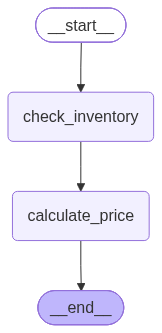

In [10]:
order_subgraph

### 1.3 Parent graph nodes


In [7]:
# Parent-graph nodes (run outside the subgraph, before/after it).
def validate_request(state: OrderState):
    print("Validating request...")

    if state["product"] not in PRODUCT_CATALOG:
        raise ValueError(f"Unknown product: {state['product']}")

    if state["quantity"] <= 0:
        raise ValueError("Quantity must be greater than zero.")

    # No state changes needed here — this node only validates/raises.
    return {}


def create_final_response(state: OrderState):
    # Reads inventory_status/total_price that were set inside the
    # order_subgraph — proof that subgraph state flows back into the parent.
    if state["inventory_status"] == "Available":
        response = (
            f"{state['quantity']} {state['product']} ordered. "
            f"Total Price: ₹{state['total_price']:,.2f}"
        )
    else:
        response = (
            f"Order not placed. {state['quantity']} "
            f"{state['product']} are not available."
        )

    return {
        "final_response": response
    }


### 1.4 Build the parent graph


In [8]:
# Build the parent graph: START -> validate_request -> order_processing
# (the whole order_subgraph) -> final_response -> END.
order_builder = StateGraph(OrderState)

order_builder.add_node(
    "validate_request",
    validate_request,
)

# The complete compiled subgraph becomes one parent node.
# Passing a compiled graph (instead of a plain function) to add_node is
# exactly what nests order_subgraph inside order_graph. Because both share
# OrderState, no manual state translation is needed.
order_builder.add_node(
    "order_processing",
    order_subgraph,
)

order_builder.add_node(
    "final_response",
    create_final_response,
)

order_builder.add_edge(
    START,
    "validate_request",
)

order_builder.add_edge(
    "validate_request",
    "order_processing",
)

order_builder.add_edge(
    "order_processing",
    "final_response",
)

order_builder.add_edge(
    "final_response",
    END,
)

order_graph = order_builder.compile()


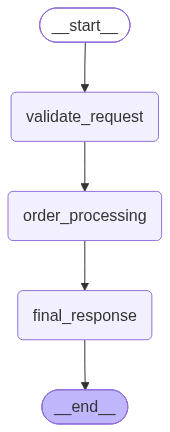

In [9]:
# In a Jupyter cell, a bare expression auto-renders its repr/HTML —
# for a compiled LangGraph graph this shows the graph diagram inline.
order_graph

### 1.5 Generated graph structure

`xray=True` expands the nested subgraph inside the parent graph. This cell does not make a model call.


In [11]:
# xray=True flattens order_processing into its two inner nodes
# (check_inventory, calculate_price) in the printed Mermaid diagram.
show_graph(
    order_graph,
    xray=True,
)


---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	validate_request(validate_request)
	final_response(final_response)
	__end__([<p>__end__</p>]):::last
	__start__ --> validate_request;
	order_processing\3acalculate_price --> final_response;
	validate_request --> order_processing\3acheck_inventory;
	final_response --> __end__;
	subgraph order_processing
	order_processing\3acheck_inventory(check_inventory)
	order_processing\3acalculate_price(calculate_price)
	order_processing\3acheck_inventory --> order_processing\3acalculate_price;
	end
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



### 1.6 Test the order workflow

**Model calls:** 0

**Expected behavior:** The request is validated, inventory is checked, the price is calculated, and the final confirmation shows ₹1,000.00.


In [12]:
# .invoke() runs the whole compiled graph synchronously with the given
# input dict as the starting state, returning the final state dict.
def run_order_workflow():
    result = order_graph.invoke(
        {
            "product": "Keyboard",
            "quantity": 2,
        }
    )

    print(result["final_response"])

    return result


In [13]:
# Run Example 1 end-to-end.
order_result = run_order_workflow()


Validating request...
Checking inventory...
Calculating price...
2 Keyboard ordered. Total Price: ₹1,000.00


**Common mistake:** A direct subgraph node works cleanly here because the parent and subgraph share the same state keys.

**Student exercise:** Change the quantity to `6` and confirm that the order is rejected because only five keyboards are available.


## 2. Parallel Research Subgraph with `Send`

### What it does

The parent graph creates one worker per topic. Each worker invokes the same research subgraph, and the parent combines all summaries.

### Why this integration is different

The parent uses `ParentState`, each worker receives `ResearchWorkerInput`, and the subgraph uses `ResearchState`. The worker acts as an adapter between these different schemas.

### Simple real-world example

A research coordinator assigns different topics to researchers. Every researcher follows the same research-and-summary process, and an instructor combines the completed summaries.


In [14]:
# Load OPENAI_API_KEY (and any other secrets) from a local .env file.
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()

# Shared LLM instance used by all research-subgraph nodes and by
# combine_results below. temperature=0 keeps outputs deterministic-ish.
model = ChatOpenAI(
    model="gpt-4.1-mini",
    temperature=0,
)

/Users/manny/Documents/git_repos/Full-stack-GenAI/env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 2.1 Parent, worker, and subgraph states


In [15]:
# Three different schemas in play here — unlike Example 1, parent, worker,
# and subgraph do NOT share one state type.

# State of the top-level graph (research_graph).
class ParentState(TypedDict):
    topics: list[str]
    # operator.add as a reducer means: when multiple parallel branches each
    # return a "research_results" update, LangGraph concatenates the lists
    # instead of one overwriting another. This is required for the Send-based
    # fan-out below, where several research_worker calls run concurrently.
    research_results: Annotated[
        list[str],
        operator.add,
    ]
    final_answer: str


# The payload shape that Send(...) delivers to each research_worker call —
# just the single topic that worker is responsible for.
class ResearchWorkerInput(TypedDict):
    topic: str


# State of the research_subgraph, invoked (not added as a node) inside
# research_worker for each topic.
class ResearchState(TypedDict):
    topic: str
    research: str
    summary: str


### 2.2 Research subgraph nodes


In [16]:
# Nodes of research_subgraph — each makes one LLM call and writes into
# ResearchState.
def research_topic(state: ResearchState):
    topic = state["topic"]
    print(f"[SUBGRAPH] Researching: {topic}")

    response = model.invoke(
        f"""
Explain this Generative AI topic: {topic}

Include:
1. A definition
2. Important concepts
3. One practical use case

Keep the explanation concise.
"""
    )

    return {
        "research": response.content
    }


def summarize_topic(state: ResearchState):
    print(f"[SUBGRAPH] Summarizing: {state['topic']}")

    # Uses the "research" field written by research_topic in the previous
    # subgraph node — same state flows linearly through the subgraph.
    response = model.invoke(
        f"""
Create a concise summary of this research.

Topic: {state['topic']}

Research:
{state['research']}
"""
    )

    return {
        "summary": response.content
    }


### 2.3 Build the research subgraph


In [17]:
# Build research_subgraph: START -> research_topic -> summarize_topic -> END.
# Note: this is compiled but never added as a node to any parent graph
# (contrast with order_subgraph in Example 1) — instead it gets manually
# .invoke()-d from inside research_worker below.
research_builder = StateGraph(ResearchState)

research_builder.add_node(
    "research_topic",
    research_topic,
)

research_builder.add_node(
    "summarize_topic",
    summarize_topic,
)

research_builder.add_edge(
    START,
    "research_topic",
)

research_builder.add_edge(
    "research_topic",
    "summarize_topic",
)

research_builder.add_edge(
    "summarize_topic",
    END,
)

research_subgraph = research_builder.compile()


### 2.4 Parent graph nodes

`Send` creates one worker input per topic. The reducer on `research_results` safely combines worker outputs.


In [18]:
# Parent-graph (research_graph) nodes.

def prepare_topics(state: ParentState):
    # Just logs the incoming topics; the real fan-out happens in
    # distribute_topics via the conditional edge below.
    print("Topics received:")

    for topic in state["topics"]:
        print(f"- {topic}")

    return {}


def research_worker(state: ResearchWorkerInput):
    # This function is the "adapter" between ParentState/ResearchWorkerInput
    # and ResearchState: it receives just {"topic": ...} (via Send) and
    # manually invokes the standalone research_subgraph with a full
    # ResearchState payload.
    topic = state["topic"]
    print(f"[WORKER] Starting: {topic}")

    subgraph_result = research_subgraph.invoke(
        {
            "topic": topic,
            "research": "",
            "summary": "",
        }
    )

    # research_results uses the operator.add reducer, so returning a
    # single-item list here gets concatenated with the lists returned by
    # the other parallel workers instead of overwriting them.
    return {
        "research_results": [
            f"## {topic}\n\n{subgraph_result['summary']}"
        ]
    }


def distribute_topics(state: ParentState):
    # Conditional-edge function: instead of naming one next node, it returns
    # a list of Send objects. Each Send("research_worker", {...}) schedules
    # a separate, parallel invocation of the research_worker node with its
    # own input — this is how one topic list turns into N workers at runtime.
    return [
        Send(
            "research_worker",
            {"topic": topic},
        )
        for topic in state["topics"]
    ]


def combine_results(state: ParentState):
    # By the time this node runs, all research_worker branches have
    # finished and their outputs have been merged (via operator.add) into
    # state["research_results"].
    combined_research = "\n\n".join(
        state["research_results"]
    )

    response = model.invoke(
        f"""
Combine these research summaries into one clear explanation.
Keep each topic under its own heading.

{combined_research}
"""
    )

    return {
        "final_answer": response.content
    }


### 2.5 Build the parent graph


In [19]:
# Build the parent graph:
# START -> prepare_topics -> [Send-based fan-out to research_worker] ->
# combine_results -> END.
research_parent_builder = StateGraph(ParentState)

research_parent_builder.add_node(
    "prepare_topics",
    prepare_topics,
)

research_parent_builder.add_node(
    "research_worker",
    research_worker,
)

research_parent_builder.add_node(
    "combine_results",
    combine_results,
)

research_parent_builder.add_edge(
    START,
    "prepare_topics",
)

# add_conditional_edges with a function that returns Send(...) objects is
# what wires up the dynamic fan-out: distribute_topics decides, at runtime,
# how many research_worker invocations to create (one per topic) and what
# input each gets. The ["research_worker"] list just tells LangGraph which
# node names this edge is allowed to route to.
research_parent_builder.add_conditional_edges(
    "prepare_topics",
    distribute_topics,
    ["research_worker"],
)

research_parent_builder.add_edge(
    "research_worker",
    "combine_results",
)

research_parent_builder.add_edge(
    "combine_results",
    END,
)

research_graph = research_parent_builder.compile()


### 2.6 Generated graph structures

The subgraph is invoked inside `research_worker`, so the parent diagram does not expand it automatically. Displaying both graphs makes the relationship clear.


In [20]:
# Show both graphs. research_graph's diagram will NOT show research_topic /
# summarize_topic nested inside research_worker (unlike Example 1's
# xray=True view) because research_subgraph was invoked manually in code,
# not registered as a node — LangGraph has no static knowledge of that call.
print("RESEARCH SUBGRAPH")
show_graph(research_subgraph)

print("PARENT GRAPH")
show_graph(research_graph)


RESEARCH SUBGRAPH
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	research_topic(research_topic)
	summarize_topic(summarize_topic)
	__end__([<p>__end__</p>]):::last
	__start__ --> research_topic;
	research_topic --> summarize_topic;
	summarize_topic --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

PARENT GRAPH
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	prepare_topics(prepare_topics)
	research_worker(research_worker)
	combine_results(combine_results)
	__end__([<p>__end__</p>]):::last
	__start__ --> prepare_topics;
	prepare_topics -.-> research_worker;
	research_worker --> combine_results;
	combine_results --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



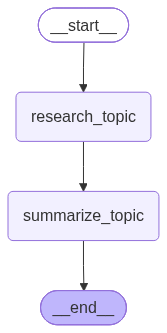

In [21]:
# Inline diagram render of the standalone research_subgraph.
research_subgraph

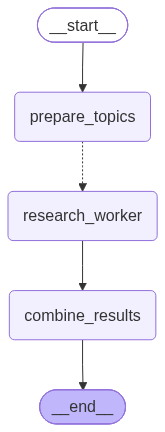

In [22]:
# Inline diagram render of the parent research_graph (dotted edge shows the
# dynamic Send-based fan-out to research_worker).
research_graph

### 2.7 Test the parallel research workflow

**Model calls:** 7 for the three-topic test: two calls per topic plus one final combination call.

**Expected behavior:** Three workers are created, each worker runs the two-node research subgraph, three results are collected, and one combined answer is printed. Worker log order may vary because the tasks can run in parallel.


In [23]:
# Note: research_results must be seeded as [] here (even though its type
# is Annotated with operator.add) — reducers combine updates, they don't
# invent an initial value.
def run_parallel_research_workflow():
    result = research_graph.invoke(
        {
            "topics": [
                "Retrieval-Augmented Generation",
                "AI Agents",
                "Memory Management",
            ],
            "research_results": [],
        }
    )

    print("\nFINAL ANSWER\n")
    print(result["final_answer"])

    return result


In [24]:
# Run Example 2 end-to-end. Watch the printed log order: [WORKER] Starting
# lines for all three topics can interleave with [SUBGRAPH] Researching /
# Summarizing lines, showing the workers executing concurrently.
research_result = run_parallel_research_workflow()


Topics received:
- Retrieval-Augmented Generation
- AI Agents
- Memory Management
[WORKER] Starting: Retrieval-Augmented Generation
[SUBGRAPH] Researching: Retrieval-Augmented Generation
[WORKER] Starting: AI Agents
[SUBGRAPH] Researching: AI Agents
[WORKER] Starting: Memory Management
[SUBGRAPH] Researching: Memory Management
[SUBGRAPH] Summarizing: AI Agents
[SUBGRAPH] Summarizing: Memory Management
[SUBGRAPH] Summarizing: Retrieval-Augmented Generation

FINAL ANSWER

Here is a combined explanation of the three research topics, organized under their respective headings:

---

### Retrieval-Augmented Generation

Retrieval-Augmented Generation (RAG) is a generative AI technique that improves large language models by integrating external information retrieval. It combines a retriever component, which fetches relevant documents from an external knowledge base, with a generator that produces responses informed by this retrieved data. Some RAG systems are trained end-to-end to jointly opti

**Common mistakes:** Removing the reducer from `research_results`, forgetting the `Send` destination list, or expecting the manually invoked subgraph to appear inside the parent diagram.

**Student exercise:** Add a fourth topic and confirm that LangGraph creates a fourth worker automatically.


In [25]:
# Note: research_results must be seeded as [] here (even though its type
# is Annotated with operator.add) — reducers combine updates, they don't
# invent an initial value.
def run_parallel_research_workflow():
    result = research_graph.invoke(
        {
            "topics": [
                "Retrieval-Augmented Generation",
                "AI Agents",
                "Memory Management",
                "LangGraph",
            ],
            "research_results": [],
        }
    )

    print("\nFINAL ANSWER\n")
    print(result["final_answer"])

    return result

In [26]:
# Run Example 2 end-to-end. Watch the printed log order: [WORKER] Starting
# lines for all three topics can interleave with [SUBGRAPH] Researching /
# Summarizing lines, showing the workers executing concurrently.
research_result = run_parallel_research_workflow()

Topics received:
- Retrieval-Augmented Generation
- AI Agents
- Memory Management
- LangGraph
[WORKER] Starting: Retrieval-Augmented Generation
[SUBGRAPH] Researching: Retrieval-Augmented Generation
[WORKER] Starting: AI Agents
[SUBGRAPH] Researching: AI Agents
[WORKER] Starting: Memory Management
[SUBGRAPH] Researching: Memory Management
[WORKER] Starting: LangGraph
[SUBGRAPH] Researching: LangGraph
[SUBGRAPH] Summarizing: AI Agents
[SUBGRAPH] Summarizing: Memory Management
[SUBGRAPH] Summarizing: Retrieval-Augmented Generation
[SUBGRAPH] Summarizing: LangGraph

FINAL ANSWER

Here is a combined explanation of the research topics, organized under their respective headings:

---

### Retrieval-Augmented Generation

Retrieval-Augmented Generation (RAG) is a generative AI technique that combines large language models with external retrieval systems to improve the accuracy and relevance of generated responses. Instead of relying solely on pre-trained knowledge, RAG dynamically fetches rele